# Análisis de Opiniones en Redes Sociales

> **Nota:** dataset ficticio de 6 opiniones en español (solo 2 quedan en el conjunto de prueba), creado para practicar la técnica. Sirve para ilustrar el procedimiento, no para sacar conclusiones generalizables.

##Preparación de los Datos

In [1]:

import pandas as pd
import numpy as np
import nltk
import string
from nltk.corpus import stopwords

# Descargar recursos
nltk.download("stopwords")

# Datos
opiniones = [
    "Este producto es excelente, me encantó",
    "Horrible, nunca lo compraría",
    "Muy bueno, lo recomiendo totalmente",
    "No me gustó, la calidad es mala",
    "Una compra increíble, vale la pena",
    "Muy malo, pésima experiencia"
]
etiquetas = np.array([1, 0, 1, 0, 1, 0])

# Preprocesamiento
def limpiar_texto(texto):
    texto = texto.lower().translate(str.maketrans("", "", string.punctuation))
    tokens = texto.split()
    tokens_limpios = [word for word in tokens if word not in stopwords.words("spanish")]
    return " ".join(tokens_limpios)

# Limpieza
opiniones_limpias = [limpiar_texto(op) for op in opiniones]
opiniones_limpias


['producto excelente encantó',
 'horrible nunca compraría',
 'bueno recomiendo totalmente',
 'gustó calidad mala',
 'compra increíble vale pena',
 'malo pésima experiencia']

## Clasificación con Scikit-learn (Naive Bayes)

Precisión Naive Bayes: 0.5

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       0.00      0.00      0.00         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



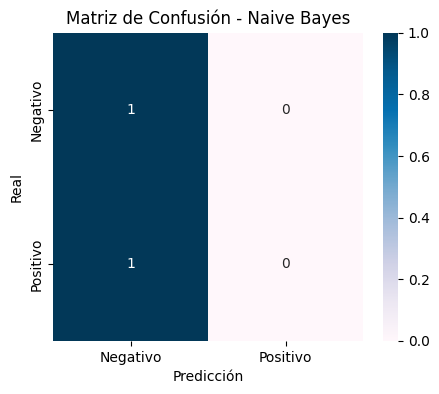

In [2]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# División
X_train, X_test, y_train, y_test = train_test_split(opiniones_limpias, etiquetas, test_size=0.2, random_state=42)

# Modelo
modelo_nb = make_pipeline(TfidfVectorizer(), MultinomialNB())
modelo_nb.fit(X_train, y_train)

# Predicción
y_pred_nb = modelo_nb.predict(X_test)

# Evaluación
print("Precisión Naive Bayes:", accuracy_score(y_test, y_pred_nb))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_nb))

# Matriz de Confusión - Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(5,4))
sns.heatmap(cm_nb, annot=True, cmap='PuBu', fmt='d', xticklabels=["Negativo", "Positivo"], yticklabels=["Negativo", "Positivo"])
plt.title('Matriz de Confusión - Naive Bayes')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()


## Clasificación con TensorFlow (Red Neuronal LSTM)

Epoch 1/10


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 721ms/step - accuracy: 0.5000 - loss: 0.6927 - val_accuracy: 0.5000 - val_loss: 0.6929
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.5000 - loss: 0.6925 - val_accuracy: 0.5000 - val_loss: 0.6929
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.5000 - loss: 0.6922 - val_accuracy: 0.5000 - val_loss: 0.6927
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.5000 - loss: 0.6919 - val_accuracy: 0.5000 - val_loss: 0.6926
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.5000 - loss: 0.6917 - val_accuracy: 0.5000 - val_loss: 0.6925
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.5000 - loss: 0.6912 - val_accuracy: 0.5000 - val_loss: 0.6924
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.5000 - loss: 0.6908 - val_accuracy: 0.5000 - val_loss: 0.6922
Epoch 

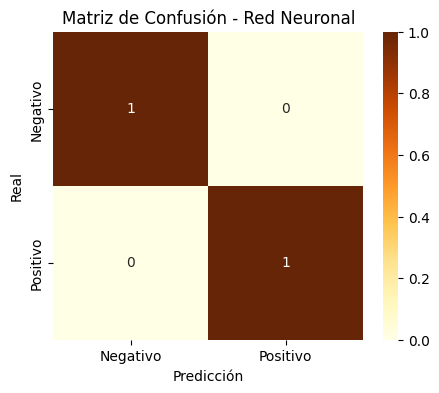

In [3]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Embedding, Dense, LSTM
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenización y Padding
tokenizer = Tokenizer(num_words=1000, oov_token="<OOV>")
tokenizer.fit_on_texts(opiniones_limpias)
sequences = tokenizer.texts_to_sequences(opiniones_limpias)
padded_sequences = pad_sequences(sequences, maxlen=10, padding='post')

# División
X_train, X_test, y_train, y_test = train_test_split(padded_sequences, etiquetas, test_size=0.2, random_state=42)

# Modelo
modelo_tf = keras.Sequential([
    Embedding(input_dim=1000, output_dim=16),
    LSTM(32),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

modelo_tf.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Entrenamiento
historial = modelo_tf.fit(X_train, y_train, epochs=10, verbose=1, validation_data=(X_test, y_test))

# Predicción
y_pred_tf = (modelo_tf.predict(X_test) > 0.5).astype("int32")

# Evaluación
print("Precisión Red Neuronal:", accuracy_score(y_test, y_pred_tf))

# Matriz de Confusión - Red Neuronal
cm_tf = confusion_matrix(y_test, y_pred_tf)
plt.figure(figsize=(5,4))
sns.heatmap(cm_tf, annot=True, cmap='YlOrBr', fmt='d', xticklabels=["Negativo", "Positivo"], yticklabels=["Negativo", "Positivo"])
plt.title('Matriz de Confusión - Red Neuronal')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()


## Gráficos de Rendimiento de la Red Neuronal

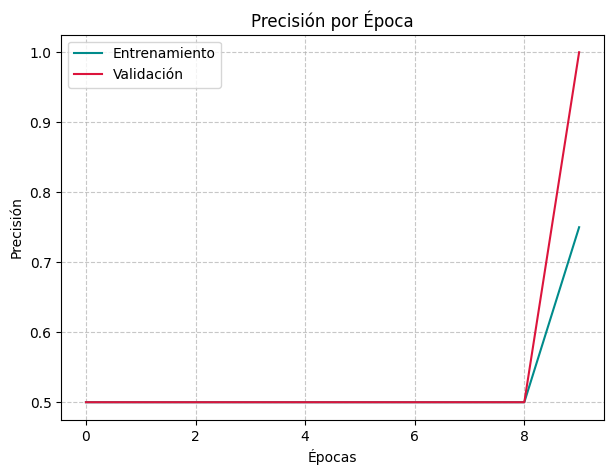

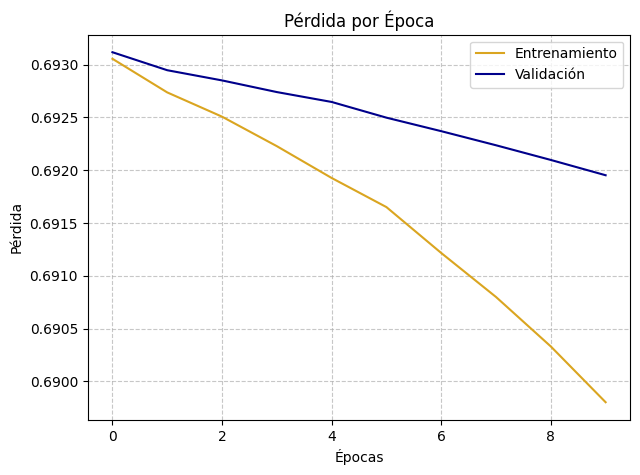

In [4]:

# Gráfico de Accuracy
plt.figure(figsize=(7,5))
plt.plot(historial.history['accuracy'], label='Entrenamiento', color='darkcyan')
plt.plot(historial.history['val_accuracy'], label='Validación', color='crimson')
plt.title('Precisión por Época')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Gráfico de Loss
plt.figure(figsize=(7,5))
plt.plot(historial.history['loss'], label='Entrenamiento', color='goldenrod')
plt.plot(historial.history['val_loss'], label='Validación', color='darkblue')
plt.title('Pérdida por Época')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


## Conclusiones y limitaciones

- Se implementó el flujo completo: limpieza de texto (minúsculas, signos de puntuación, *stopwords*), clasificación con TF-IDF + Naive Bayes y con una red neuronal LSTM.
- **Los resultados no son significativos:** con 6 opiniones, el conjunto de prueba tiene 2 casos. Naive Bayes obtiene 50 % (azar) y la LSTM llega a 100 % solo por casualidad en la última época: la pérdida se mantiene en ≈ 0,69 durante todo el entrenamiento, es decir, la red prácticamente no aprendió.
- Para un resultado real hacen falta cientos o miles de opiniones etiquetadas, y comparar contra un modelo de referencia.